# CodeGuard AI — Experiment 08: Final system evaluation

Compares **Bandit**, **ML** and **both combined** on (A) hand-labelled fixtures and (B) real CVE-fix code,
then scores (C) the RAG + LLM explanations and fixes and (D) speed. Results are saved to
`artifacts/metrics/system_evaluation.json`.

*Outputs are from the full run of this notebook. On 29 Oct 2026 two display-only cells and library warning
messages were removed to shorten it; no result changed.*

In [1]:
import io
import json
import re
import statistics
import sys
import tempfile
import time
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from codeguard.pipeline import InputError, bandit_to_findings, scan
from codeguard.repo.repo_scanner import scan_repository
from codeguard.scanner import ml_detector
from codeguard.scanner.static_analyzer import run_bandit_dir
from codeguard.schemas import Severity

model, card = ml_detector.load_model()
THRESHOLD = card["threshold"]
FIX = ROOT / "tests" / "fixtures"
print("ML model:", card["model_version"], "| threshold", THRESHOLD)

def ml_flags(code_text: str) -> bool:
    try:
        units = ml_detector.extract_units(code_text, min_lines=1)
    except SyntaxError:
        return False
    return any(s.flagged for s in ml_detector.score_units(units, model=model, threshold=THRESHOLD))

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    tp, fp = int((y_true & y_pred).sum()), int((~y_true & y_pred).sum())
    fn, tn = int((y_true & ~y_pred).sum()), int((~y_true & ~y_pred).sum())
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(tp / (tp + fp), 3) if tp + fp else None,
            "recall": round(tp / (tp + fn), 3) if tp + fn else None,
            "false_positive_rate": round(fp / (fp + tn), 3) if fp + tn else None,
            "f1": round(2 * tp / (2 * tp + fp + fn), 3) if tp else 0.0}

IMPORT_ONLY = re.compile(r"^B4\d\d$")   # 'import pickle' etc. are reminders, not detections

ML model: py-tfidf-logistic-v2-20261015 | threshold 0.5456


## A. Hand-labelled fixtures (12 vulnerable / 11 safe files)

Flagged by Bandit = any finding except import-only reminders (B4xx). Flagged by ML = any function above the
v2 threshold. Combined = either.

In [2]:
rows = []
for label, folder in ((1, "vulnerable"), (0, "safe")):
    for path in sorted((FIX / folder).glob("*.py")):
        text = path.read_text()
        res = scan(text, path.name, use_ml=False)
        bandit = any(not IMPORT_ONLY.match(f.rule_id) for f in res.findings)
        rows.append({"file": path.name, "vulnerable": label, "bandit": bandit, "ml": ml_flags(text)})
fixtures = pd.DataFrame(rows)
fixtures["combined"] = fixtures["bandit"] | fixtures["ml"]
fixture_table = pd.DataFrame({e: metrics(fixtures["vulnerable"], fixtures[e]) for e in ["bandit", "ml", "combined"]}).T
fixture_table

,TP,FP,FN,TN,precision,recall,false_positive_rate,f1
bandit,12.0,1.0,0.0,10.0,0.923,1.000,0.091,0.960
ml,8.0,2.0,4.0,9.0,0.800,0.667,0.182,0.727
combined,12.0,3.0,0.0,8.0,0.800,1.000,0.273,0.889


## B. Real CVE-fix code (726 held-out methods = 363 vulnerable/fixed pairs)

Methods from repositories the model never saw. Besides precision and recall we ask the **pair question**:
does an engine flag the vulnerable version but *not* its fix?

In [4]:
raw = pd.read_csv(ROOT / "datasets" / "processed" / "python_functions.csv")
KEY = ["commit_hash", "file_path", "method_name"]
sizes = raw.groupby(KEY)["target"].agg(n="size", vulnerable="sum")
pairs = raw.set_index(KEY).loc[sizes[(sizes["n"] == 2) & (sizes["vulnerable"] == 1)].index].reset_index()
pairs["code_key"] = pairs["func"].str.replace(r"\s+", "", regex=True)
changed = pairs.groupby(KEY)["code_key"].nunique() == 2
pairs = pairs.set_index(KEY).loc[changed[changed].index].reset_index()
TEST_PATH = re.compile(r"(^|/)(tests?|testing|unit_tests)/|(^|/)test_[^/]*\.py$|_tests?\.py$|(^|/)conftest\.py$")
TEST_NAME = re.compile(r"^(test|_test|setUp|tearDown|setUpClass|tearDownClass)")
is_test = pairs["file_path"].str.contains(TEST_PATH) | pairs["method_name"].str.contains(TEST_NAME)
pairs = pairs[~pairs.groupby(KEY)["file_path"].transform(lambda s: is_test.loc[s.index].any())]
conflict = pairs.groupby("code_key")["target"].nunique()
pairs = pairs[~pairs["code_key"].isin(conflict[conflict > 1].index)]
pairs = pairs[pairs.groupby(KEY)["target"].transform("size") == 2].copy()
pairs["pair_id"] = pairs.groupby(KEY).ngroup()
df = pairs.reset_index(drop=True)
from sklearn.model_selection import GroupShuffleSplit
_, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(df, df["target"], df["repo_url"]))
test = df.iloc[test_idx].reset_index(drop=True)
print(len(test), "methods,", test["pair_id"].nunique(), "pairs,", test["repo_url"].nunique(), "repositories")

726 methods, 363 pairs, 69 repositories


In [5]:
import textwrap
start = time.time()
with tempfile.TemporaryDirectory() as tmp:
    names = []
    for i, code_text in enumerate(test["func"]):
        name = f"m{i:04d}.py"
        # Methods are extracted from classes, so dedent them to make each a valid module on its own.
        (Path(tmp) / name).write_text(textwrap.dedent(code_text), encoding="utf-8")
        names.append(name)
    report = run_bandit_dir(Path(tmp))
issues = {}
for issue in report.issues:
    issues.setdefault(Path(issue["filename"]).name, []).append(issue)
parse_errors = len(report.errors)
print(f"Bandit over {len(names)} methods in {time.time() - start:.1f} s; {parse_errors} could not be parsed")

def bandit_flags(i, min_severity=None):
    name = names[i]
    found = bandit_to_findings(issues.get(name, []), textwrap.dedent(test["func"][i]), name)
    found = [f for f in found if not IMPORT_ONLY.match(f.rule_id)]
    if min_severity:
        found = [f for f in found if f.severity.rank <= min_severity.rank]
    return found

test["bandit_all"] = [bool(bandit_flags(i)) for i in range(len(test))]
test["bandit_medium"] = [bool(bandit_flags(i, Severity.MEDIUM)) for i in range(len(test))]
test["ml_score"] = model.predict_proba(test["func"])[:, 1]
test["ml"] = test["ml_score"] >= THRESHOLD
test["combined_or"] = test["bandit_medium"] | test["ml"]
test["combined_and"] = test["bandit_all"] & test["ml"]
engines = {"Bandit (all rules)": "bandit_all", "Bandit (Medium+)": "bandit_medium", "ML v2": "ml",
           "Combined: Bandit Medium+ OR ML": "combined_or", "Combined: Bandit AND ML": "combined_and"}
real_table = pd.DataFrame({name: metrics(test["target"], test[col]) for name, col in engines.items()}).T
real_table

Bandit over 726 methods in 16.8 s; 28 could not be parsed


,TP,FP,FN,TN,precision,recall,false_positive_rate,f1
Bandit (all rules),71.0,66.0,292.0,297.0,0.518,0.196,0.182,0.284
Bandit (Medium+),43.0,19.0,320.0,344.0,0.694,0.118,0.052,0.202
ML v2,37.0,29.0,326.0,334.0,0.561,0.102,0.080,0.172
Combined: Bandit Medium+ OR ML,70.0,47.0,293.0,316.0,0.598,0.193,0.129,0.292
Combined: Bandit AND ML,12.0,3.0,351.0,360.0,0.800,0.033,0.008,0.063


In [6]:
def pair_outcomes(col):
    p = test.pivot_table(index="pair_id", columns="target", values=col, aggfunc="first")
    return {"flags vulnerable only (correct)": int((p[1] & ~p[0]).sum()), "flags both": int((p[1] & p[0]).sum()),
            "flags fixed only (wrong)": int((~p[1] & p[0]).sum()), "flags neither": int((~p[1] & ~p[0]).sum())}
pair_table = pd.DataFrame({name: pair_outcomes(col) for name, col in engines.items()}).T
pair_table

,flags vulnerable only (correct),flags both,flags fixed only (wrong),flags neither
Bandit (all rules),10,61,5,287
Bandit (Medium+),28,15,4,316
ML v2,15,22,7,319
Combined: Bandit Medium+ OR ML,33,37,10,283
Combined: Bandit AND ML,9,3,0,351


In [7]:
vuln = test[test["target"] == 1].assign(cwe=lambda d: d["cwe_id"].str.split(",")).explode("cwe")
per_cwe = vuln.groupby("cwe").agg(methods=("id", "size"), bandit_recall=("bandit_all", "mean"), ml_recall=("ml", "mean"))
per_cwe[per_cwe["methods"] >= 8].sort_values("methods", ascending=False).round(2)

,methods,bandit_recall,ml_recall
cwe,,,
NVD-CWE-noinfo,94,0.38,0.14
CWE-94,32,0.19,0.00
CWE-400,30,0.07,0.07
CWE-22,19,0.21,0.32
CWE-79,16,0.06,0.19
CWE-502,15,0.00,0.13
CWE-74,13,0.00,0.00
CWE-287,11,0.00,0.09
CWE-601,11,0.00,0.27


Bandit rules fired on the 726 methods: [('B307', 272), ('B102', 183), ('B608', 162), ('B110', 80), ('B101', 63), ('B603', 28), ('B602', 20), ('B311', 6), ('B605', 4), ('B607', 4)]


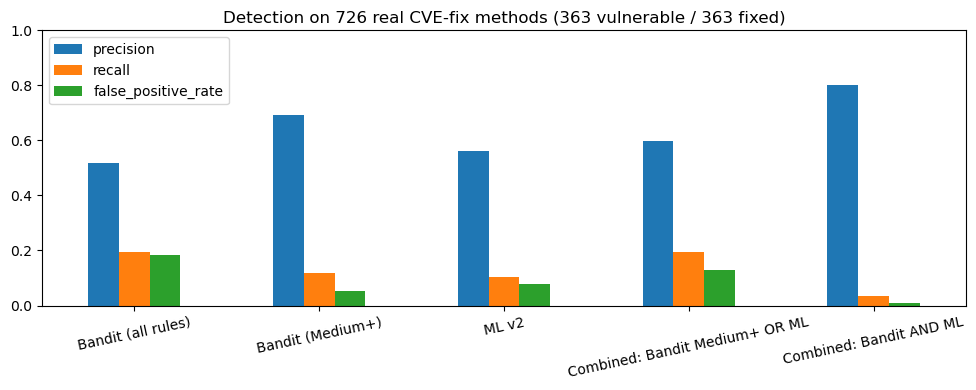

In [8]:
fired = Counter(f.rule_id for i in range(len(test)) for f in bandit_flags(i))
print("Bandit rules fired on the 726 methods:", fired.most_common(10))
fig, ax = plt.subplots(figsize=(10, 4))
real_table[["precision", "recall", "false_positive_rate"]].astype(float).plot.bar(ax=ax, rot=12)
ax.set_title("Detection on 726 real CVE-fix methods (363 vulnerable / 363 fixed)")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "system_detection.png", dpi=120)
plt.show()

## C. Explanations and fixes (18 findings, local LLM)

Automatic rubric: *valid JSON*, *grounded* (cites only the provided sources), *on topic* (mentions the
weakness) and *fix passes checks* (parses, finding removed, nothing new at Medium/High). The human rubric is in
`Documents/Explanation_Evaluation.docx`.

In [9]:
from codeguard.llm.client import get_client, LLMUnavailable
from codeguard.llm.explainer import explain
from codeguard.remediation import fix_validator

KEYWORDS = {"Code injection": r"eval|exec|arbitrary code|code injection|inject",
            "Command injection": r"command|shell|inject", "SQL injection": r"sql|inject|query",
            "Unsafe deserialization": r"deserial|pickle|yaml|untrusted", "Hardcoded secret": r"password|secret|credential|hard-?coded",
            "Weak cryptography": r"md5|sha1|hash|weak|collision", "TLS / certificate validation": r"certificate|tls|ssl|verif|man-in-the-middle|mitm",
            "Insecure temporary file": r"temp|race|predictable", "Weak randomness": r"random|predict|cryptograph",
            "Denial of service": r"timeout|hang|denial", "Code quality": r"assert|optimi|-O"}
try:
    client = get_client()
    print("LLM:", client.provider, client.model)
except LLMUnavailable as exc:
    client = None
    print("No LLM available:", exc)

cases = []
for path in sorted((FIX / "vulnerable").glob("*.py")):
    text = path.read_text()
    f = next(f for f in scan(text, path.name, use_ml=False).findings if not IMPORT_ONLY.match(f.rule_id))
    cases.append(("fixture", path.name, text, f))
seen_rules = {f.rule_id for *_, f in cases}
for i in range(len(test)):
    if test["target"][i] != 1:
        continue
    for f in bandit_flags(i, Severity.MEDIUM):
        if f.rule_id not in seen_rules or len(cases) < 18:
            cases.append(("cvefixes", names[i], textwrap.dedent(test["func"][i]), f))
            seen_rules.add(f.rule_id)
            break
    if len(cases) >= 18:
        break
print(len(cases), "cases:", Counter(src for src, *_ in cases))

LLM: ollama llama3.2


18 cases: Counter({'fixture': 12, 'cvefixes': 6})


In [10]:
records = []
for src, name, text, f in cases:
    t0 = time.time()
    res = explain(f, text, client=client) if client else explain(f, text)
    seconds = time.time() - t0
    e = res.explanation
    blob = " ".join([e.summary, e.why_dangerous, e.exploit_conditions]).lower()
    fix = fix_validator.propose_template_fix(text, f, name)
    if fix is None and res.mode == "llm":
        fix = fix_validator.propose_llm_fix(text, f, res, name)
    records.append({
        "source": src, "file": name, "rule": f.rule_id, "category": f.category, "mode": res.mode,
        "seconds": round(seconds, 1), "valid_json": res.mode == "llm",
        "grounded": bool(e.citations) and not res.invalid_citations,
        "on_topic": bool(re.search(KEYWORDS.get(f.category, f.category.lower()), blob)),
        "fix_origin": fix.origin if fix else "none", "fix_status": fix.status if fix else "none",
        "summary": e.summary, "why_dangerous": e.why_dangerous, "exploit_conditions": e.exploit_conditions,
        "fix_explanation": e.fix_explanation, "citations": e.citations,
        "sources": [f"{s.id}: {s.title}" for s in res.sources], "diff": fix.diff if fix else "",
    })
    print(f"{f.rule_id:5} {res.mode:15} {seconds:5.0f}s grounded={records[-1]['grounded']} "
          f"on_topic={records[-1]['on_topic']} fix={records[-1]['fix_origin']}/{records[-1]['fix_status']}")
expl = pd.DataFrame(records)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

B307  llm                47s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B102  llm                28s grounded=True on_topic=True fix=llm/requires_review


B105  llm                26s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B324  llm                25s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B306  llm                20s grounded=True on_topic=True fix=llm/requires_review


... (9 outputs left out)

B307  llm                34s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B307  llm                29s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B307  llm                35s grounded=True on_topic=True fix=rule_template/passed_configured_checks


B301  llm                30s grounded=True on_topic=True fix=llm/passed_configured_checks


In [11]:
auto = {
    "cases": len(expl), "valid JSON (LLM answered)": expl["valid_json"].mean(), "grounded": expl["grounded"].mean(),
    "on topic": expl["on_topic"].mean(),
    "fix proposed": (expl["fix_origin"] != "none").mean(),
    "fix passed checks": (expl["fix_status"] == "passed_configured_checks").mean(),
    "template fixes passed": (expl.query("fix_origin == 'rule_template'")["fix_status"] == "passed_configured_checks").mean(),
    "LLM fixes passed": (expl.query("fix_origin == 'llm'")["fix_status"] == "passed_configured_checks").mean()
        if (expl["fix_origin"] == "llm").any() else None,
    "median seconds per explanation": float(expl["seconds"].median()),
}
explanation_table = pd.Series(auto).round(3)
explanation_table

cases                             18.000
valid JSON (LLM answered)          1.000
grounded                           0.944
on topic                           1.000
fix proposed                       1.000
fix passed checks                  0.667
template fixes passed              1.000
LLM fixes passed                   0.333
median seconds per explanation    28.150
dtype: float64

## D. Speed and reliability

In [13]:
timings, failures, rejected = [], 0, 0
for path in sorted(FIX.rglob("*")):
    if not path.is_file():
        continue
    t0 = time.perf_counter()
    try:
        res = scan(path.read_bytes(), path.name)
        failures += res.engines["bandit"].status != "ok"
        timings.append((time.perf_counter() - t0) * 1000)
    except InputError:
        rejected += 1
    except Exception:
        failures += 1
buffer = io.BytesIO()
with zipfile.ZipFile(buffer, "w") as archive:
    for p in (FIX / "vulnerable").glob("*.py"):
        archive.write(p, f"proj/{p.name}")
    for p in (FIX / "safe").glob("*.py"):
        archive.write(p, f"proj/safe/{p.name}")
t0 = time.perf_counter()
repo = scan_repository(buffer.getvalue(), "fixtures.zip")
repo_ms = (time.perf_counter() - t0) * 1000
speed = {"single-file scans": len(timings), "median single-file scan (ms)": round(statistics.median(timings)),
         "inputs rejected with a clear error": rejected, "crashes / engine failures": failures,
         "repository scan: files": len(repo.files), "repository scan (ms)": round(repo_ms)}
speed

{'single-file scans': 25,
 'median single-file scan (ms)': 289,
 'inputs rejected with a clear error': 7,
 'crashes / engine failures': 0,
 'repository scan: files': 23,
 'repository scan (ms)': 443}

In [14]:
import platform
out = {
    "fixtures": fixture_table.reset_index(names="engine").to_dict(orient="records"),
    "cvefixes_test": {"methods": len(test), "pairs": int(test["pair_id"].nunique()),
                      "engines": real_table.reset_index(names="engine").to_dict(orient="records"),
                      "pairs_outcomes": pair_table.reset_index(names="engine").to_dict(orient="records"),
                      "bandit_rules_fired": dict(fired)},
    "explanations": {k: (None if v is None or (isinstance(v, float) and np.isnan(v)) else v) for k, v in auto.items()},
    "speed": speed, "ml_model": card["model_version"], "llm": f"{client.provider}:{client.model}" if client else None,
    "environment": f"Python {platform.python_version()}, {platform.system()} {platform.release()}, CPU only",
}
(ROOT / "artifacts" / "metrics" / "system_evaluation.json").write_text(json.dumps(out, indent=2, default=str))
expl.to_json(ROOT / "artifacts" / "metrics" / "explanations_sample.json", orient="records", indent=2)
print("Saved artifacts/metrics/system_evaluation.json and explanations_sample.json")

Saved artifacts/metrics/system_evaluation.json and explanations_sample.json


## Conclusion

| | Result |
|---|---|
| **Fixtures** | Bandit precision 0.923, recall **1.000** (one Low false alarm on a safe list-argument subprocess call). ML adds only false alarms here |
| **Real CVE code** | Recall **10–20%** for every engine. Bandit Medium+ OR ML flags the most pairs correctly (**33**, vs 28 for Bandit alone) at FPR 13% vs 5% |
| **Complementary** | ML catches open redirect 27%, path traversal 32%, XSS 19% where Bandit has 0%, 21%, 6% |
| **Explanations** | 18/18 valid, 17/18 grounded, 18/18 on topic, median 28 s |
| **Fixes** | Rule templates **9/9** passed; LLM fixes **3/9**, every failure caught by the validator |
| **Speed** | Median 289 ms per file; 23-file repository in 443 ms; 0 crashes, 7 bad inputs rejected |

Caveats: 449 of the 455 `eval`/`exec` hits come from one project (docassemble); 28 method fragments could not
be parsed and count as "not flagged".

**Overall:** reliable and fast for known Python risk patterns, with grounded explanations and checked fixes,
but not a general vulnerability detector: most real CVEs were missed by every engine.